In [ ]:
# 最初にこのセルを実行：状態読み込み → 全次元の分類 → 混同行列
# 入力・保存先を変える場合は、このセルのSOURCE_DIR・OUTPUT_DIRを変更する。
from pathlib import Path
import sys
import os
import json
import hashlib
import time

# h_analysis内から開いても、プロジェクト直下から開いても動くようにする。
cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents]
             if (p / 'd_tools' / 'pca.py').is_file()
             and (p / 'c_configs' / 'FIXED' / 'calibration_reference.npz').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('LSM_liquid内を作業フォルダとして実行してください。')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from d_tools.component_evaluation import evaluate_component_counts

if 'get_ipython' in globals() and get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
print('Project:', ROOT)
print('Python:', sys.executable)

SOURCE_DIR = ROOT / 'g_tactile_results' / 'gain179_sequential_calibration_20261019' / 'all_materials'
REFERENCE_FILE = ROOT / 'c_configs' / 'FIXED' / 'calibration_reference.npz'
OUTPUT_DIR = ROOT / 'h_analysis' / 'results' / 'gain179_incremental_pca_accuracy'
FEATURE_KEY = 'counts_25ms'
NEURON_IDS = np.arange(80)  # E0〜E79。抑制性は含めない。
BIN_MS = 25.0
MAX_PCS = 40
REGULARIZATION = 1e-6
THREADS = 4
RECOMPUTE = False  # 同一の入力・解析コードなら保存済みの計算を再利用。

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MATERIALS = json.loads(REFERENCE_FILE.with_suffix('.json').read_text(encoding='utf-8'))['materials']
print('Input:', SOURCE_DIR)
print('Output:', OUTPUT_DIR)

reference_metadata = json.loads(REFERENCE_FILE.with_suffix('.json').read_text(encoding='utf-8'))
assert hashlib.sha256(REFERENCE_FILE.read_bytes()).hexdigest() == reference_metadata['sha256']
with np.load(REFERENCE_FILE) as data:
    trial_order = data['trial_order'].copy()
    train_indices = data['train_indices'].copy()
    test_indices = data['test_indices'].copy()

state_parts, feature_files = [], []
for material_index, material in enumerate(MATERIALS):
    path = SOURCE_DIR / material / 'features.npz'
    with np.load(path) as data:
        counts = data[FEATURE_KEY]
        ids = data['trial_ids']
    if len(np.unique(ids)) != len(ids):
        raise ValueError(f'{material}: 試行IDが重複しています。')
    by_id = {int(sid): i for i, sid in enumerate(ids)}
    positions = [by_id[int(sid)] for sid in trial_order[material_index]]
    state_parts.append(counts[positions][:, NEURON_IDS, :] / (BIN_MS / 1000.0))
    feature_files.append(path)

n_classes = len(MATERIALS)
n_trials_per_material = len(trial_order[0])
states = np.concatenate(state_parts, axis=0)
labels = np.repeat(np.arange(n_classes), n_trials_per_material)
splits = [(np.concatenate([m*n_trials_per_material+tr for m in range(n_classes)]),
           np.concatenate([m*n_trials_per_material+te for m in range(n_classes)]))
          for tr, te in zip(train_indices, test_indices)]
n_splits = len(splits)
n_train_each, n_test_each = train_indices.shape[1], test_indices.shape[1]
n_features = int(np.prod(states.shape[1:]))
assert states.shape == (2592, 80, 20)
assert (n_splits, n_train_each, n_test_each) == (10, 226, 98)
display(pd.DataFrame({'Material': MATERIALS,
    'Trials': n_trials_per_material, 'Training / split': n_train_each,
    'Test / split': n_test_each}))
print('States:', states.shape, '| Original features:', n_features)


# 全1600次元の分類（PCA・標準化なし）。10分割の評価結果を加算する。
from threadpoolctl import threadpool_limits
from d_tools.classification import classify
from d_tools.evaluation import evaluate_classification, confusion_percentages
from d_tools.plotting import save_confusion_matrix
from IPython.display import Image

full_feature_matrix = states.reshape(len(states), -1)
full_confusion_counts = np.zeros((n_classes, n_classes), dtype=np.int64)
full_confusion_folds = []
full_confusion_predictions = []
with threadpool_limits(limits=THREADS):
    for fold, (training_ids, evaluation_ids) in enumerate(splits, 1):
        train_x = full_feature_matrix[training_ids]
        # 過去の解析と同じく、学習側で一度も活動しない特徴だけを除く。
        active = np.any(train_x != 0, axis=0)
        predicted = classify(train_x[:, active], labels[training_ids],
                             full_feature_matrix[evaluation_ids][:, active],
                             regularization=REGULARIZATION)
        metrics = evaluate_classification(labels[evaluation_ids], predicted,
                                          labels=np.arange(n_classes))
        full_confusion_counts += metrics['confusion_matrix']
        full_confusion_folds.append({'fold': fold, 'accuracy': metrics['accuracy']})
        full_confusion_predictions.append(pd.DataFrame({
            'fold': fold, 'ordered_trial_index': evaluation_ids,
            'true_material': np.asarray(MATERIALS)[labels[evaluation_ids]],
            'predicted_material': np.asarray(MATERIALS)[predicted],
        }))
        print(f'[Full features] split {fold}/{n_splits}: {metrics["accuracy"]:.2%}')

assert np.all(full_confusion_counts.sum(axis=1) == n_splits*n_test_each)
full_confusion_accuracy = float(np.trace(full_confusion_counts)/full_confusion_counts.sum())
full_confusion_percent = confusion_percentages(full_confusion_counts)
confusion_title = (
    f'{len(NEURON_IDS)} excitatory neurons | All {n_features} features\n'
    f'Accuracy: {full_confusion_accuracy:.2%} | {n_splits} holdouts; '
    f'{n_test_each} test trials/material/split'
)
confusion_png_path = OUTPUT_DIR / 'confusion_full_features.png'
save_confusion_matrix(full_confusion_counts, MATERIALS, confusion_png_path,
                      title=confusion_title, dpi=180)
pd.DataFrame(full_confusion_counts, index=MATERIALS, columns=MATERIALS).rename_axis(
    'True material').to_csv(OUTPUT_DIR / 'confusion_full_features_counts.csv')
pd.DataFrame(full_confusion_percent, index=MATERIALS, columns=MATERIALS).rename_axis(
    'True material').to_csv(OUTPUT_DIR / 'confusion_full_features_percent.csv')
pd.DataFrame(full_confusion_folds).to_csv(OUTPUT_DIR / 'confusion_full_features_accuracy_by_split.csv', index=False)
pd.concat(full_confusion_predictions, ignore_index=True).to_csv(
    OUTPUT_DIR / 'confusion_full_features_predictions.csv', index=False)
display(Image(filename=str(confusion_png_path)))
print(f'Full-feature accuracy: {full_confusion_accuracy:.4%}')
print('Saved:', confusion_png_path)
# 各行は1素材あたり98試行×10分割=980件。同じ試行が別の分割で再登場する場合がある。


# 主成分数と素材分類正答率

保存済みのリキッド応答から、PC1、PC1〜PC2、…、PC1〜PC40を使った分類正答率を比較します。
リキッド層の再シミュレーションとgain探索は行いません。

- 興奮性80ニューロン、25 msビン、8素材×324試行。
- 各素材226試行を学習、98試行を評価に使う従来と同じ10回の分割。
- 標準化なし。各分割の学習データだけで平均とPCA軸を求めます。
- 分類器は正則化マハラノビス分類（正則化係数 `1e-6`）。
- 青：PCAの平均正答率±分割間の標本標準偏差。黒破線：全特徴の平均正答率。灰色点線：一様ランダム分類。

カーネルは **Python (LSM_liquid)** またはこのプロジェクトの `.mlflow-venv` を選び、上からすべて実行してください。
添付の97.30%は以前の条件の数値です。このノートブックでは現在選択した結果から再計算します。

最初のコードセルで状態の読込と全次元の混同行列を作成します。その後、PC数別の解析セルへ進みます。


## 1．使う結果と解析条件

現在の採用条件：入力gain179、EE0.150、EI0.206、IE0.01390625、II0。
各試行で状態を初期化した `all_materials` の発火数を使います。
別の実験結果を調べる場合は、下の `SOURCE_DIR` と保存先を変更してください。


## 2．状態を読み込み、従来と同じ試行順・分割へそろえる

各25 msビンのスパイク数を0.025秒で割ってHzへ変換します。
状態の形は「2592試行×80ニューロン×20時間ビン」で、PCA内部では1試行1600特徴になります。
分割の添字は各素材内の試行順に対応するため、保存済みの試行順にそろえてから分割します。


## 3．PC数を1〜40へ増やして分類する

各分割で学習時に一度も活動しなかった特徴を除外し、PCAを一度だけ計算します。
PC1〜PCkの先頭k列を使い、各kで分類器を学習し直します。全特徴の分類にも同じ分割を使います。
評価データは、特徴の選択・平均・PCA軸・分類器の学習には使いません。

同じ入力ファイルと解析コードなら、次回は保存済みCSVを読み込みます。
入力やコードが変わった場合は、自動で再計算します。


In [4]:
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

tool_files = [ROOT / 'd_tools' / name for name in
              ['pca.py', 'classification.py', 'evaluation.py', 'component_evaluation.py']]
signature_data = {
    'source': str(SOURCE_DIR), 'feature_key': FEATURE_KEY, 'bin_ms': BIN_MS,
    'neuron_ids': NEURON_IDS.tolist(), 'max_pcs': MAX_PCS,
    'regularization': REGULARIZATION,
    'input_sha256': {str(p.relative_to(ROOT)): sha256(p) for p in feature_files},
    'reference_sha256': sha256(REFERENCE_FILE),
    'tool_sha256': {p.name: sha256(p) for p in tool_files},
}
signature = hashlib.sha256(json.dumps(signature_data, sort_keys=True).encode()).hexdigest()
detail_path = OUTPUT_DIR / 'accuracy_by_split.csv'
meta_path = OUTPUT_DIR / 'analysis_metadata.json'
reuse = (not RECOMPUTE and detail_path.exists() and meta_path.exists()
         and json.loads(meta_path.read_text(encoding='utf-8')).get('signature') == signature)
start = time.perf_counter()
if reuse:
    results = pd.read_csv(detail_path)
    print('同じ入力・条件の保存済み結果を読み込みました。')
else:
    results = evaluate_component_counts(states, labels, splits,
        n_components=MAX_PCS, regularization=REGULARIZATION, threads=THREADS)
    results.to_csv(detail_path, index=False)
    metadata = {'signature': signature, **signature_data,
                'standardization': False, 'pca_training_only': True,
                'n_splits': n_splits, 'n_train_per_material': n_train_each,
                'n_test_per_material': n_test_each,
                'state_policy': 'reset_each_trial',
                'elapsed_seconds': time.perf_counter()-start}
    meta_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
assert len(results) == n_splits*(MAX_PCS+1)
assert results.groupby('fold').size().eq(MAX_PCS+1).all()
print(f'完了：{n_splits}分割 × 全特徴＋{MAX_PCS}条件 | {time.perf_counter()-start:.1f}秒')


Split 1/10 | Full: 98.98% | PC1-PC40: 98.60% | 1.0 s


Split 2/10 | Full: 98.98% | PC1-PC40: 97.83% | 1.0 s


Split 3/10 | Full: 97.58% | PC1-PC40: 96.43% | 1.0 s


Split 4/10 | Full: 99.74% | PC1-PC40: 99.11% | 0.8 s


Split 5/10 | Full: 99.87% | PC1-PC40: 99.36% | 0.8 s


...

Split 7/10 | Full: 99.74% | PC1-PC40: 99.11% | 0.8 s


Split 8/10 | Full: 97.83% | PC1-PC40: 97.07% | 0.8 s


Split 9/10 | Full: 99.62% | PC1-PC40: 99.11% | 0.8 s


Split 10/10 | Full: 99.23% | PC1-PC40: 99.11% | 0.8 s


完了：10分割 × 全特徴＋40条件 | 8.6秒


## 4．集計と保存済み分類との照合

誤差棒は10分割間の標本標準偏差（ddof=1）です。信頼区間ではありません。
全特徴とPC40は、同じ条件の保存済み分類があれば分割ごとに一致を確認します。


In [5]:
pca_results = results[results.representation.eq('PCA')]
full_results = results[results.representation.eq('full_features')]
summary = pca_results.groupby('n_pcs').accuracy.agg(['mean', 'std']).reset_index()
summary['mean_accuracy_percent'] = summary['mean']*100
summary['std_accuracy_percent'] = summary['std']*100
summary.to_csv(OUTPUT_DIR / 'accuracy_by_pc_count.csv', index=False)
baseline_accuracy = float(full_results.accuracy.mean())
baseline_std = float(full_results.accuracy.std(ddof=1))

previous_path = SOURCE_DIR / 'classification' / 'accuracy_by_split.csv'
if previous_path.exists():
    previous = pd.read_csv(previous_path)
    if 'condition' in previous:
        previous = previous[previous.condition.eq('retuned')]
    for representation, current in [('full_features', full_results),
                                    ('PC40', pca_results[pca_results.n_pcs.eq(MAX_PCS)])]:
        old = previous[previous.representation.eq(representation)].sort_values('fold')
        if len(old) == n_splits:
            np.testing.assert_allclose(current.sort_values('fold').accuracy.to_numpy(),
                                       old.accuracy.to_numpy(), rtol=0, atol=1e-12)
            print(f'{representation}: 保存済み10分割の正答率と一致')

print(f'全{n_features}特徴：{baseline_accuracy*100:.4f}% ± {baseline_std*100:.4f}%')
display(summary[['n_pcs', 'mean_accuracy_percent', 'std_accuracy_percent']].round(4))


full_features: 保存済み10分割の正答率と一致
PC40: 保存済み10分割の正答率と一致
全1600特徴：99.1454% ± 0.8333%


,n_pcs,mean_accuracy_percent,std_accuracy_percent
0,1,39.0051,0.8371
1,2,58.3163,0.7858
2,3,84.1454,0.9565
3,4,86.4668,0.8428
4,5,88.2781,0.9246
5,6,89.8724,0.9182
6,7,90.4592,0.8018
7,8,91.1480,1.0843
8,9,93.6862,1.1221
9,10,94.5663,1.3217


## 5．グラフを作る

図中の表記は英語、横軸は `Number of PCs`。下段の累積寄与率グラフは付けません。
薄い青線は各分割、青い点と誤差棒は平均±標準偏差です。


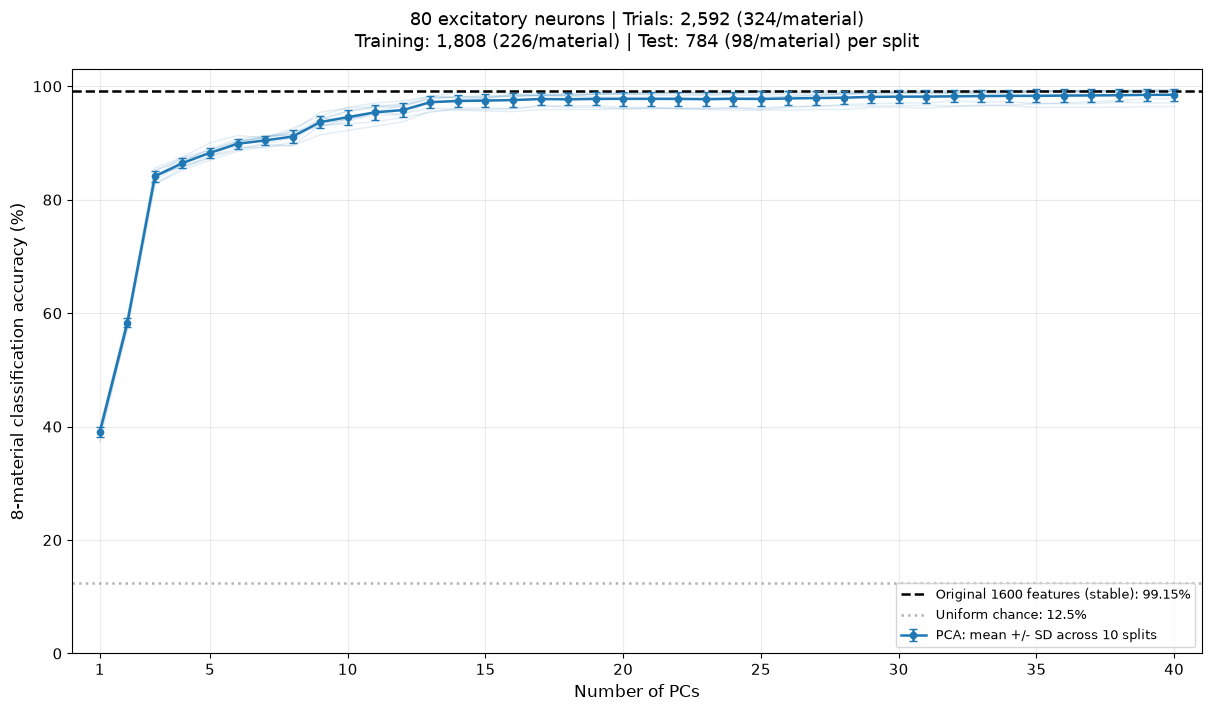

PNG: C:\Users\haru4\研究\研究コード\LSM_liquid\h_analysis\results\gain179_incremental_pca_accuracy\incremental_pca_accuracy_01_40.png
SVG: C:\Users\haru4\研究\研究コード\LSM_liquid\h_analysis\results\gain179_incremental_pca_accuracy\incremental_pca_accuracy_01_40.svg
Table: C:\Users\haru4\研究\研究コード\LSM_liquid\h_analysis\results\gain179_incremental_pca_accuracy\accuracy_by_pc_count.csv


In [6]:
with plt.rc_context({'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 12}):
    fig, ax = plt.subplots(figsize=(12, 7), layout='constrained')
    for fold, group in pca_results.groupby('fold'):
        group = group.sort_values('n_pcs')
        ax.plot(group.n_pcs, group.accuracy*100, color='tab:blue', alpha=.13, lw=1)
    ax.axhline(baseline_accuracy*100, color='black', ls='--', lw=1.8,
               label=f'Original {n_features} features (stable): {baseline_accuracy*100:.2f}%')
    ax.axhline(100/n_classes, color='0.7', ls=':', lw=1.8,
               label=f'Uniform chance: {100/n_classes:g}%')
    ax.errorbar(summary.n_pcs, summary.mean_accuracy_percent,
                yerr=summary.std_accuracy_percent, fmt='o-', color='tab:blue',
                markersize=4.5, lw=1.8, capsize=3,
                label=f'PCA: mean +/- SD across {n_splits} splits')
    ax.set(xlabel='Number of PCs', ylabel=f'{n_classes}-material classification accuracy (%)',
           xlim=(0, MAX_PCS+1), ylim=(0, 103))
    ax.set_xticks([1, *range(5, MAX_PCS+1, 5)])
    ax.grid(True, alpha=.25)
    ax.set_title(f'{len(NEURON_IDS)} excitatory neurons | Trials: {len(states):,} '
                 f'({n_trials_per_material}/material)\n'
                 f'Training: {n_classes*n_train_each:,} ({n_train_each}/material) | '
                 f'Test: {n_classes*n_test_each:,} ({n_test_each}/material) per split', pad=16)
    ax.legend(loc='lower right', fontsize=9)
    png_path = OUTPUT_DIR / 'incremental_pca_accuracy_01_40.png'
    svg_path = OUTPUT_DIR / 'incremental_pca_accuracy_01_40.svg'
    fig.savefig(png_path, dpi=180)
    fig.savefig(svg_path)
    plt.show()
print('PNG:', png_path)
print('SVG:', svg_path)
print('Table:', OUTPUT_DIR / 'accuracy_by_pc_count.csv')
